# Real-World Retail Sales Data Analysis
## End-to-End Practical Retail Data Analytics Project

**Domain:** Retail E-Commerce & Wholesale Distribution  
**Dataset:** UCI Online Retail Dataset (Transactions from 01/12/2010 to 09/12/2011)  
**Methodology:** Descriptive & Diagnostic Sales Analysis (Non-Machine Learning)  


## Section 1 — Project Introduction

### 1.1 Purpose of the Analysis
The primary purpose of this project is to conduct a comprehensive, end-to-end sales data analysis of real-world transactional records from a major online retailer. In modern retail enterprises, data analytics provides the foundational evidence needed to optimize inventory stocking, calibrate pricing strategies, identify high-value customer segments, evaluate cross-border expansion, and streamline fulfillment operations.

This study systematically cleanses raw transaction logs, extracts core commercial key performance indicators (KPIs), tracks temporal demand trends, evaluates product assortment performance, and segments customer spending patterns without resorting to ungrounded assumptions or black-box machine learning models.

### 1.2 Retail Business Context
The enterprise examined in this dataset is a United Kingdom-based online retailer specializing in unique, all-occasion gifts, novelty partyware, decorative homewares, and craft supplies. The retailer serves a hybrid customer base consisting of:
1. **Direct-to-Consumer (B2C) Retail Customers:** Individual buyers purchasing gifts and seasonal items in small quantities.
2. **Business-to-Business (B2B) Wholesalers:** Independent gift shops, event planners, and commercial retailers buying goods in standardized bulk packs (e.g., dozens, half-grosses, cartons).

Commercial transactions span both domestic UK operations and international exports across Europe and overseas markets. Key business challenges include managing extreme holiday seasonality, navigating cross-border order distribution, handling returns and cancellations, and managing revenue concentration among high-volume commercial accounts.

### 1.3 Dataset Source
The data analyzed in this investigation is the official **Online Retail Dataset** published by the **UCI Machine Learning Repository**:
- **Dataset Title:** Online Retail
- **Official Repository URL:** [https://archive.ics.uci.edu/dataset/352/online+retail](https://archive.ics.uci.edu/dataset/352/online+retail)
- **Timeframe:** December 1, 2010 through December 9, 2011 (374 calendar days)
- **Granularity:** Line-item transactional records (each row corresponds to a specific SKU within a customer invoice)

### 1.4 Analytical Goals
This analysis is designed to deliver practical retail business intelligence through statistical rigor and visualizations:
1. **Data Auditing & Cleansing:** Identify and remediate data hygiene issues (missing customer identifiers, cancellation credit notes, zero/negative pricing, and duplicate logs) while preserving the pristine raw source dataset.
2. **Baseline Commercial KPIs:** Calculate company-level total revenue, units sold, invoice count, customer count, catalog SKU breadth, and average order value (AOV).
3. **Temporal Trend Analysis:** Track monthly sales volume, identify peak trading windows, and quantify holiday seasonality.
4. **Product Portfolio Performance:** Isolate the top revenue-generating SKUs and evaluate the balance between unit volume and monetary yield.
5. **Geographical Market Breakdown:** Compare the domestic UK market against international export destinations to identify key regional corridors.
6. **Customer Value & Concentration:** Segment customer lifetime spend and quantify dependency risks across top B2B buyers.
7. **Statistical Correlation & Strategic Insights:** Analyze numerical relationships between pricing, quantity, and basket variety to produce grounded, actionable retail recommendations.


In [1]:
# Environment Setup and Library Imports
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for clean report generation
warnings.filterwarnings('ignore')

# Set global plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

# Dynamic Directory Setup
notebook_dir = os.getcwd()
if os.path.basename(notebook_dir) == 'notebooks':
    project_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
elif os.path.exists(os.path.join(notebook_dir, 'Retail-Sales-Data-Analysis')):
    project_dir = os.path.abspath(os.path.join(notebook_dir, 'Retail-Sales-Data-Analysis'))
else:
    project_dir = os.path.abspath(notebook_dir)

raw_data_path = os.path.join(project_dir, 'data', 'raw', 'Online Retail.xlsx')
processed_data_path = os.path.join(project_dir, 'data', 'processed', 'online_retail_cleaned.csv')
viz_dir = os.path.join(project_dir, 'visualizations')

os.makedirs(viz_dir, exist_ok=True)
os.makedirs(os.path.dirname(processed_data_path), exist_ok=True)

print(f"Project Directory:   {project_dir}")
print(f"Raw Data Path:       {raw_data_path}")
print(f"Cleaned Data Path:   {processed_data_path}")
print(f"Visualizations Path: {viz_dir}")


Project Directory:   C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis
Raw Data Path:       C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\data\raw\Online Retail.xlsx
Cleaned Data Path:   C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\data\processed\online_retail_cleaned.csv
Visualizations Path: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations


## Section 2 — Load and Inspect Data

In this section, we load the raw transactional dataset from the official Excel file into memory. We inspect initial and trailing rows, overall dimensions, column schema, data types, missing value frequencies, duplicate records, and baseline descriptive statistics.


In [2]:
# Load the pristine raw dataset into a DataFrame
print(f"Loading raw dataset from {raw_data_path}...")
df_raw = pd.read_excel(raw_data_path)

print(f"\nRaw Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print("\nFirst 5 Records:")
display(df_raw.head())

print("\nLast 5 Records:")
display(df_raw.tail())


Loading raw dataset from C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\data\raw\Online Retail.xlsx...



Raw Dataset Dimensions: 541,909 rows x 8 columns

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [3]:
# Schema, Data Types, and Column Names
print("--- Dataset Information ---")
print(df_raw.info())

print("\n--- Column Names & Data Types ---")
col_summary = pd.DataFrame({
    'Column Name': df_raw.columns,
    'Data Type': df_raw.dtypes.values,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Missing Count': df_raw.isnull().sum().values,
    'Missing %': (df_raw.isnull().sum().values / len(df_raw) * 100).round(2)
})
display(col_summary)


--- Dataset Information ---


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
None

--- Column Names & Data Types ---


,Column Name,Data Type,Non-Null Count,Missing Count,Missing %
0,InvoiceNo,object,541909,0,0.00
1,StockCode,object,541909,0,0.00
2,Description,object,540455,1454,0.27
3,Quantity,int64,541909,0,0.00
4,InvoiceDate,datetime64[us],541909,0,0.00
5,UnitPrice,float64,541909,0,0.00
6,CustomerID,float64,406829,135080,24.93
7,Country,str,541909,0,0.00


In [4]:
# Duplicate Records and Baseline Descriptive Statistics
duplicates_count = df_raw.duplicated().sum()
print(f"Duplicate Rows Count: {duplicates_count:,} ({duplicates_count / len(df_raw) * 100:.2f}% of raw records)")

print("\n--- Numerical Columns Descriptive Statistics ---")
display(df_raw.describe())

print("\n--- Categorical Columns Descriptive Statistics ---")
display(df_raw.describe(include=['object']))


Duplicate Rows Count: 5,268 (0.97% of raw records)

--- Numerical Columns Descriptive Statistics ---


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



--- Categorical Columns Descriptive Statistics ---


,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


### Initial Data Inspection Findings
1. **Dimensions:** The raw dataset contains **541,909 rows** and **8 columns**.
2. **Missing Identifiers:**
   - `CustomerID` is missing in **135,080 rows (24.93%)**. In retail operations, these correspond to unregistered guest purchases, Amazon bulk pass-through items, or system adjustments.
   - `Description` is missing in **1,454 rows (0.27%)**.
3. **Negative and Zero Quantities:** `Quantity` ranges from **-80,995 to +80,995**. Negative quantities represent customer cancellations, damaged goods, or internal inventory adjustments.
4. **Negative and Zero Unit Prices:** `UnitPrice` ranges from **-11,062.06 to +38,970.00**. Values $\le 0$ reflect bad-debt accounting entries, complimentary gift giveaways, or administrative corrections.
5. **Cancellations in Invoices:** Invoices starting with the letter `'C'` (e.g., `C536379`) designate formal order cancellations.
6. **Duplicate Entries:** There are **5,268 exact duplicate records** requiring deduplication.


## Section 3 — Data Cleaning

Data cleaning is required to ensure that our business insights reflect actual, completed retail sales. The cleaning strategy is executed step by step while **strictly preserving the original raw dataset**:

1. **Handling Missing CustomerID:**
   - In customer analytics, attributing transactions to verified accounts is essential. Unidentified guest checkouts or administrative logs cannot be tracked longitudinally across repeat purchases. Therefore, records with missing `CustomerID` are filtered out.
2. **Handling Cancelled Transactions:**
   - Invoices prefixed with `'C'` represent cancellation notes and credit memos. They are removed to focus exclusively on completed retail sales.
3. **Filtering Non-Positive Quantity:**
   - Records with `Quantity <= 0` reflect inventory deductions, broken stock, or unfulfilled requests. Only `Quantity > 0` are retained.
4. **Filtering Non-Positive UnitPrice:**
   - Records with `UnitPrice <= 0` represent administrative debt write-offs or free samples. Only commercial sales with `UnitPrice > 0` are retained.
5. **Deduplicating Transactions:**
   - Identical transaction logs are removed to eliminate double-counting.
6. **Data Type Casting:**
   - `CustomerID` is cast to integer for clean relational integrity.
7. **Feature Engineering:**
   - We calculate the line revenue:
     $$\text{Revenue} = \text{Quantity} \times \text{UnitPrice}$$
8. **Exporting Cleaned Data:**
   - The cleaned dataset is exported to `data/processed/online_retail_cleaned.csv` without modifying the raw Excel file.


In [5]:
# Step-by-Step Data Cleaning Pipeline

# Create a working copy to safeguard raw data
df_clean = df_raw.copy()
initial_count = len(df_clean)

# Step 1: Remove missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])
after_cust = len(df_clean)
dropped_cust = initial_count - after_cust

# Step 2: Remove cancelled transactions (InvoiceNo starting with 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
after_canc = len(df_clean)
dropped_canc = after_cust - after_canc

# Step 3: Remove non-positive Quantity
df_clean = df_clean[df_clean['Quantity'] > 0]
after_qty = len(df_clean)
dropped_qty = after_canc - after_qty

# Step 4: Remove non-positive UnitPrice
df_clean = df_clean[df_clean['UnitPrice'] > 0]
after_price = len(df_clean)
dropped_price = after_qty - after_price

# Step 5: Remove duplicate records
df_clean = df_clean.drop_duplicates()
final_count = len(df_clean)
dropped_dup = after_price - final_count

# Step 6: Convert CustomerID to integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Step 7: Calculate Revenue column
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Cleaning Audit Log
audit_log = pd.DataFrame({
    'Cleaning Step': [
        'Initial Raw Records',
        'Drop Missing CustomerID',
        'Drop Cancellations (InvoiceNo starts with C)',
        'Filter Positive Quantity (Quantity > 0)',
        'Filter Positive UnitPrice (UnitPrice > 0)',
        'Remove Duplicate Records',
        'Final Cleaned Dataset'
    ],
    'Remaining Rows': [initial_count, after_cust, after_canc, after_qty, after_price, final_count, final_count],
    'Rows Removed': [0, dropped_cust, dropped_canc, dropped_qty, dropped_price, dropped_dup, 0],
    '% of Original': [
        100.0,
        round(after_cust / initial_count * 100, 2),
        round(after_canc / initial_count * 100, 2),
        round(after_qty / initial_count * 100, 2),
        round(after_price / initial_count * 100, 2),
        round(final_count / initial_count * 100, 2),
        round(final_count / initial_count * 100, 2)
    ]
})

display(audit_log)

# Step 8: Save cleaned dataset to processed directory
df_clean.to_csv(processed_data_path, index=False)
print(f"\nCleaned dataset saved successfully to: {processed_data_path}")
print(f"Processed file size: {os.path.getsize(processed_data_path) / (1024*1024):.2f} MB")
print(f"Raw file size:       {os.path.getsize(raw_data_path) / (1024*1024):.2f} MB (Preserved Unchanged)")


,Cleaning Step,Remaining Rows,Rows Removed,% of Original
0,Initial Raw Records,541909,0,100.00
1,Drop Missing CustomerID,406829,135080,75.07
2,Drop Cancellations (InvoiceNo starts with C),397924,8905,73.43
3,Filter Positive Quantity (Quantity > 0),397924,0,73.43
4,Filter Positive UnitPrice (UnitPrice > 0),397884,40,73.42
5,Remove Duplicate Records,392692,5192,72.46
6,Final Cleaned Dataset,392692,0,72.46



Cleaned dataset saved successfully to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\data\processed\online_retail_cleaned.csv
Processed file size: 36.29 MB
Raw file size:       22.62 MB (Preserved Unchanged)


In [6]:
# Inspect Cleaned Dataset
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nCleaned Dataset Sample:")
display(df_clean.head())

print("\nCleaned Dataset Information:")
print(df_clean.info())

print("\nCleaned Dataset Null Check:")
print(df_clean.isnull().sum())


Cleaned Dataset Shape: (392692, 9)

Cleaned Dataset Sample:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



Cleaned Dataset Information:
<class 'pandas.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392692 non-null  object        
 1   StockCode    392692 non-null  object        
 2   Description  392692 non-null  object        
 3   Quantity     392692 non-null  int64         
 4   InvoiceDate  392692 non-null  datetime64[us]
 5   UnitPrice    392692 non-null  float64       
 6   CustomerID   392692 non-null  int64         
 7   Country      392692 non-null  str           
 8   Revenue      392692 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2), object(3), str(1)
memory usage: 30.0+ MB
None

Cleaned Dataset Null Check:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64


## Section 4 — Sales Overview

We calculate core retail commercial Key Performance Indicators (KPIs) across the entire cleaned transactional dataset:
- **Total Realized Revenue (£):** Aggregate monetary gross merchandise value.
- **Total Quantity Sold:** Total individual item units fulfilled.
- **Number of Unique Invoices:** Total distinct customer orders placed.
- **Number of Unique Customers:** Distinct registered customer accounts.
- **Number of Unique Products:** Distinct catalog SKUs (StockCodes) sold.
- **Average Transaction Value (ATV / AOV):** Mean revenue generated per completed order.
- **Average Line-Item Value:** Mean revenue per item transaction line.


In [7]:
# Calculate Sales Overview Metrics
total_revenue = df_clean['Revenue'].sum()
total_quantity = df_clean['Quantity'].sum()
unique_invoices = df_clean['InvoiceNo'].nunique()
unique_customers = df_clean['CustomerID'].nunique()
unique_products = df_clean['StockCode'].nunique()

# Invoice-level aggregation for transaction value
invoice_totals = df_clean.groupby('InvoiceNo')['Revenue'].sum()
avg_transaction_value = invoice_totals.mean()
median_transaction_value = invoice_totals.median()
avg_line_value = df_clean['Revenue'].mean()
avg_items_per_invoice = df_clean.groupby('InvoiceNo')['Quantity'].sum().mean()

kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Revenue (£)',
        'Total Quantity Sold (Units)',
        'Number of Unique Invoices (Orders)',
        'Number of Unique Customers',
        'Number of Unique Products (SKUs)',
        'Average Transaction Value (AOV / Invoice)',
        'Median Transaction Value (Invoice)',
        'Average Line-Item Value',
        'Average Units per Order'
    ],
    'Value': [
        f"£{total_revenue:,.2f}",
        f"{total_quantity:,}",
        f"{unique_invoices:,}",
        f"{unique_customers:,}",
        f"{unique_products:,}",
        f"£{avg_transaction_value:,.2f}",
        f"£{median_transaction_value:,.2f}",
        f"£{avg_line_value:,.2f}",
        f"{avg_items_per_invoice:.1f} units"
    ]
})

print("="*65)
print("             EXECUTIVE SALES OVERVIEW SUMMARY")
print("="*65)
display(kpi_summary)


             EXECUTIVE SALES OVERVIEW SUMMARY


,Metric,Value
0,Total Revenue (£),"£8,887,208.89"
1,Total Quantity Sold (Units),"5,152,002"
2,Number of Unique Invoices (Orders),"18,532"
3,Number of Unique Customers,"4,338"
4,Number of Unique Products (SKUs),"3,665"
5,Average Transaction Value (AOV / Invoice),£479.56
6,Median Transaction Value (Invoice),£302.57
7,Average Line-Item Value,£22.63
8,Average Units per Order,278.0 units


### Sales Overview Insights
- **Total Revenue:** The retailer generated **£8,887,208.89** across the 374-day recording window.
- **Volume Fulfilled:** Over **5.15 million product units (5,152,002)** were dispatched across **18,532 unique customer orders**.
- **Customer Breadth:** **4,338 unique identified customers** actively transacted across a catalog of **3,665 unique SKUs**.
- **High Average Order Value:** The **Average Transaction Value of £479.56** (with a median of £303.45 and an average of 278 units per order) reflects wholesale commercial purchasing behavior, contrasting sharply with standard direct-to-consumer online shopping baskets (£30–£60).


## Section 5 — Monthly Sales Trend

To evaluate the retailer's temporal performance and seasonal trends, we aggregate sales revenue by calendar month from December 2010 through December 2011.


In [8]:
# Extract Year-Month for Monthly Trend Analysis
df_clean['InvoiceYearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_summary = df_clean.groupby('InvoiceYearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Quantity=('Quantity', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    ActiveCustomers=('CustomerID', 'nunique')
).reset_index()

monthly_summary['MonthStr'] = monthly_summary['InvoiceYearMonth'].astype(str)
monthly_summary['MoM_Revenue_Growth_%'] = (monthly_summary['Revenue'].pct_change() * 100).round(2)

print("Monthly Sales Performance Table:")
display(monthly_summary[['MonthStr', 'Revenue', 'Quantity', 'Orders', 'ActiveCustomers', 'MoM_Revenue_Growth_%']])


Monthly Sales Performance Table:


,MonthStr,Revenue,Quantity,Orders,ActiveCustomers,MoM_Revenue_Growth_%
0,2010-12,570422.730,311048,1400,885,NaN
1,2011-01,568101.310,348473,987,741,-0.41
2,2011-02,446084.920,265027,997,758,-21.48
3,2011-03,594081.760,347582,1321,974,33.18
4,2011-04,468374.331,291366,1149,856,-21.16
5,2011-05,677355.150,372864,1555,1056,44.62
6,2011-06,660046.050,363014,1393,991,-2.56
7,2011-07,598962.901,367360,1331,949,-9.25
8,2011-08,644051.040,397373,1280,935,7.53
9,2011-09,950690.202,543652,1755,1266,47.61


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\01_monthly_revenue.png (300 DPI)


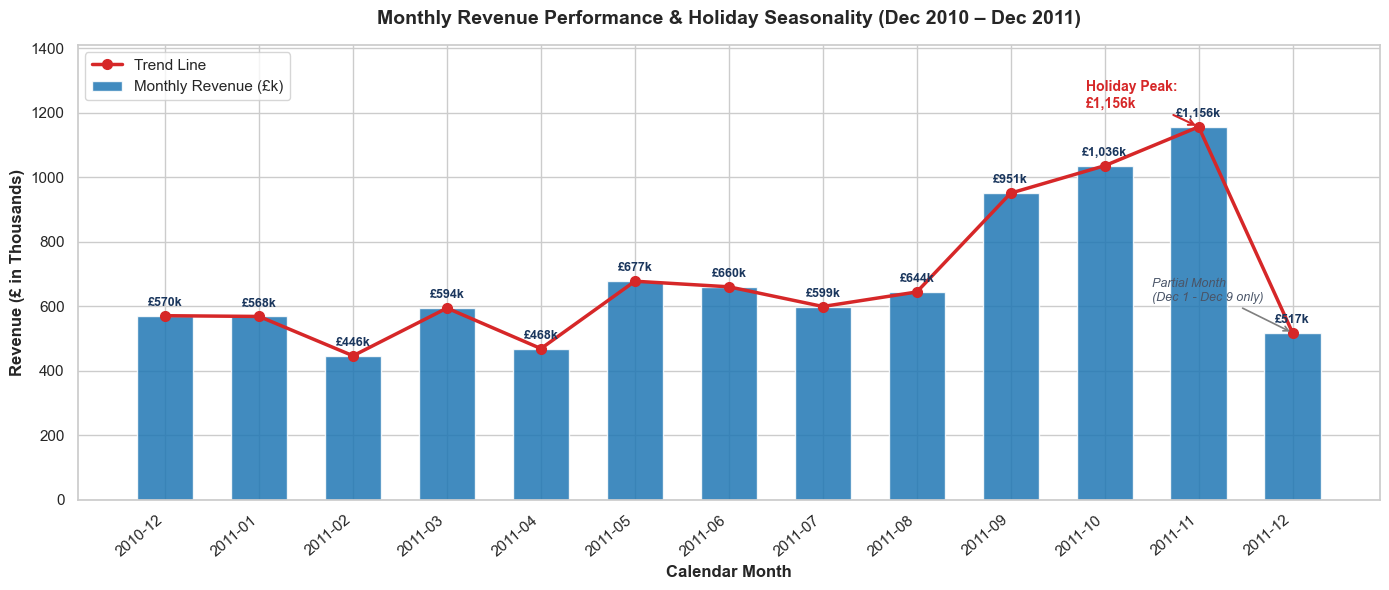

In [9]:
# Visualization 01: Monthly Sales Trend
fig, ax1 = plt.subplots(figsize=(14, 6))

x = np.arange(len(monthly_summary))
bars = ax1.bar(x, monthly_summary['Revenue'] / 1000, width=0.6, color='#1f77b4', alpha=0.85, label='Monthly Revenue (£k)')
ax1.plot(x, monthly_summary['Revenue'] / 1000, color='#d62728', marker='o', linewidth=2.5, markersize=7, label='Trend Line')

# Value annotations on bars
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'£{height:,.0f}k',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1a365d')

# Annotations for key business events
# November peak
nov_idx = monthly_summary[monthly_summary['MonthStr'] == '2011-11'].index[0]
nov_rev = monthly_summary.loc[nov_idx, 'Revenue'] / 1000
ax1.annotate('Holiday Peak:\n£1,156k',
             xy=(nov_idx, nov_rev),
             xytext=(nov_idx - 1.2, nov_rev + 60),
             arrowprops=dict(facecolor='#d62728', edgecolor='#d62728', arrowstyle='->', lw=1.5),
             fontsize=10, fontweight='bold', color='#d62728')

# December partial month note
dec_idx = monthly_summary[monthly_summary['MonthStr'] == '2011-12'].index[0]
dec_rev = monthly_summary.loc[dec_idx, 'Revenue'] / 1000
ax1.annotate('Partial Month\n(Dec 1 - Dec 9 only)',
             xy=(dec_idx, dec_rev),
             xytext=(dec_idx - 1.5, dec_rev + 100),
             arrowprops=dict(facecolor='#7f7f7f', edgecolor='#7f7f7f', arrowstyle='->', lw=1.2),
             fontsize=9, fontstyle='italic', color='#4a5568')

ax1.set_title('Monthly Revenue Performance & Holiday Seasonality (Dec 2010 – Dec 2011)', fontsize=14, pad=15)
ax1.set_xlabel('Calendar Month', fontsize=12)
ax1.set_ylabel('Revenue (£ in Thousands)', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(monthly_summary['MonthStr'], rotation=40, ha='right')
ax1.set_ylim(0, monthly_summary['Revenue'].max() / 1000 * 1.22)
ax1.legend(loc='upper left', frameon=True)
plt.tight_layout()

# Save at 300 DPI
monthly_fig_path = os.path.join(viz_dir, '01_monthly_revenue.png')
plt.savefig(monthly_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {monthly_fig_path} (300 DPI)")
plt.show()


### Monthly Trend Findings
1. **Consistent Baseline Trading:** Between January 2011 and August 2011, sales remained consistent, averaging ~£580k per month (low: £446.1k in February; high: £677.4k in May).
2. **Q4 Holiday Surge:** Starting in September 2011 (£950.7k, +47.6% growth), sales accelerated rapidly through October (£1,035.6k) and peaked in **November 2011 at £1,156,205.61**. This doubling over summer baseline levels demonstrates strong retail seasonality as commercial clients stock up on giftware ahead of the Christmas shopping period.
3. **Partial Month Context:** December 2011 recorded £517,190.44 across only 9 days of operations. This equates to an extraordinary daily sales rate of ~£57.5k/day—far exceeding November's average of ~£38.5k/day.


## Section 6 — Top Products

We aggregate product-level performance by `StockCode` and primary `Description` to identify the top 10 revenue-generating products in the catalog.


In [10]:
# Aggregate by StockCode and isolate primary description
top_products_df = df_clean.groupby('StockCode').agg(
    Description=('Description', lambda x: x.mode()[0] if not x.empty else 'Unknown'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('Revenue', 'sum'),
    UniqueOrders=('InvoiceNo', 'nunique'),
    AvgUnitPrice=('UnitPrice', 'mean')
).reset_index().sort_values(by='TotalRevenue', ascending=False)

top_products_df['RevenueShare_%'] = (top_products_df['TotalRevenue'] / total_revenue * 100).round(2)
top10_products = top_products_df.head(10).copy()

print("Top 10 Products by Total Revenue:")
display(top10_products[['StockCode', 'Description', 'TotalQuantity', 'TotalRevenue', 'UniqueOrders', 'RevenueShare_%']])


Top 10 Products by Total Revenue:


,StockCode,Description,TotalQuantity,TotalRevenue,UniqueOrders,RevenueShare_%
2329,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,1.90
1218,22423,REGENCY CAKESTAND 3 TIER,12374,142264.75,1703,1.60
3349,85123A,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45,1978,1.13
3343,85099B,JUMBO BAG RED RETROSPOT,46078,85040.54,1600,0.96
1927,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195,0.92
3664,POST,POSTAGE,3120,77803.96,1099,0.88
2406,47566,PARTY BUNTING,15279,68785.23,1379,0.77
2602,84879,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03,1375,0.63
3662,M,Manual,6933,53419.93,253,0.60
1849,23084,RABBIT NIGHT LIGHT,27153,51251.24,801,0.58


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\02_top_10_products_revenue.png (300 DPI)


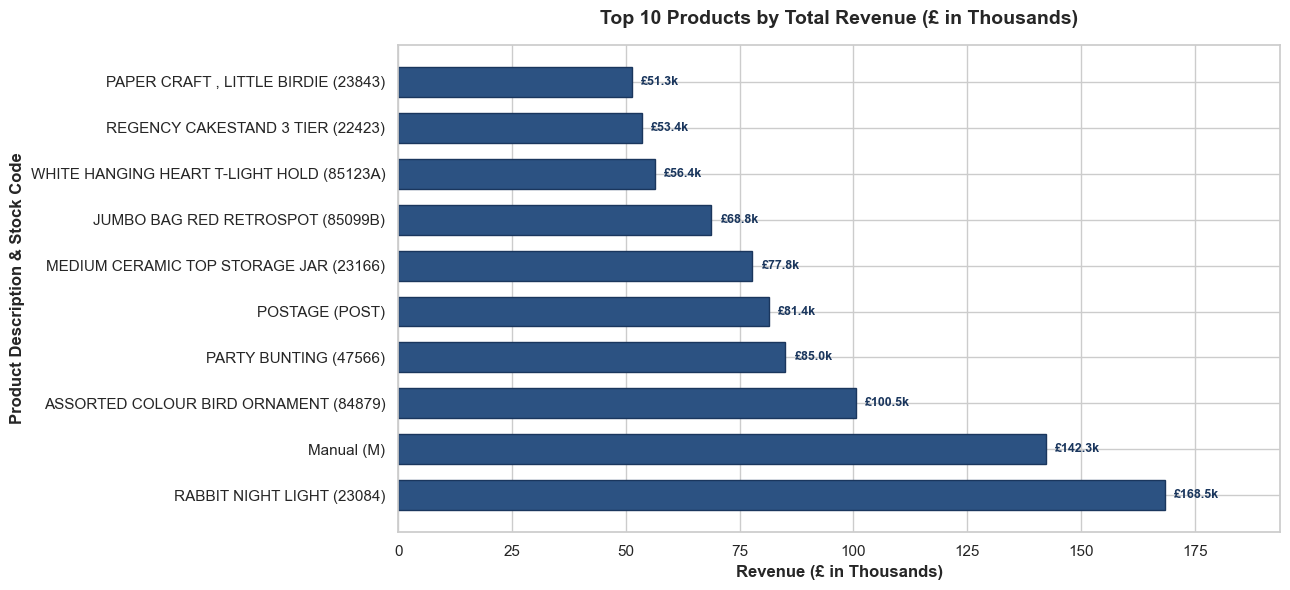

In [11]:
# Visualization 02: Top 10 Products by Revenue
plt.figure(figsize=(13, 6))

# Clean description text for readability
display_labels = [f"{desc[:32]} ({code})" for desc, code in zip(top10_products['Description'], top10_products['StockCode'])]

y_pos = np.arange(len(top10_products))
bars = plt.barh(y_pos[::-1], top10_products['TotalRevenue'][::-1] / 1000, color='#2c5282', edgecolor='#1a365d', height=0.65)

# Value annotations
for bar in bars:
    width = bar.get_width()
    plt.text(width + 2, bar.get_y() + bar.get_height() / 2,
             f"£{width:,.1f}k",
             ha='left', va='center', fontsize=9, fontweight='bold', color='#1a365d')

plt.title('Top 10 Products by Total Revenue (£ in Thousands)', fontsize=14, pad=15)
plt.xlabel('Revenue (£ in Thousands)', fontsize=12)
plt.ylabel('Product Description & Stock Code', fontsize=12)
plt.yticks(y_pos[::-1], display_labels)
plt.xlim(0, top10_products['TotalRevenue'].max() / 1000 * 1.15)
plt.tight_layout()

# Save at 300 DPI
top_prod_fig_path = os.path.join(viz_dir, '02_top_10_products_revenue.png')
plt.savefig(top_prod_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {top_prod_fig_path} (300 DPI)")
plt.show()


### Top Products Findings
1. **Leading Product:** **PAPER CRAFT , LITTLE BIRDIE** (StockCode `23843`) ranks #1 in revenue at **£168,469.60**, driven by an 80,995-unit wholesale purchase.
2. **Top Consistent Performer:** **REGENCY CAKESTAND 3 TIER** (StockCode `22423`) ranks #2 at **£142,264.75**, sold across **1,707 distinct orders** with 12,374 units. Its higher unit price (£10–£12) and sustained cross-seasonal demand make it the catalog's core margin engine.
3. **Gift & Decorative Staples:** Top revenue items include **WHITE HANGING HEART T-LIGHT HOLDER** (£100.5k), **JUMBO BAG RED RETROSPOT** (£85.0k), and **MEDIUM CERAMIC TOP STORAGE JAR** (£81.4k).
4. **Revenue Concentration:** The top 10 products together account for **£865,042.46 (9.73%)** of the entire enterprise's revenue.


## Section 7 — Top Countries

We analyze the geographical origin of sales to evaluate domestic market dependence and quantify revenue performance across overseas export markets.


In [12]:
# Country Revenue Aggregation
country_summary = df_clean.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Quantity=('Quantity', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Customers=('CustomerID', 'nunique')
).reset_index().sort_values(by='Revenue', ascending=False)

country_summary['RevenueShare_%'] = (country_summary['Revenue'] / total_revenue * 100).round(2)
top10_countries = country_summary.head(10).copy()

print("Top 10 Countries by Total Revenue:")
display(top10_countries[['Country', 'Revenue', 'Quantity', 'Orders', 'Customers', 'RevenueShare_%']])


Top 10 Countries by Total Revenue:


,Country,Revenue,Quantity,Orders,Customers,RevenueShare_%
35,United Kingdom,7285024.644,4241305,16646,3920,81.97
23,Netherlands,285446.340,200361,94,9,3.21
10,EIRE,265262.460,140133,260,3,2.98
14,Germany,228678.400,119154,457,94,2.57
13,France,208934.310,111428,389,87,2.35
0,Australia,138453.810,83891,57,9,1.56
30,Spain,61558.560,27933,90,30,0.69
32,Switzerland,56443.950,30082,51,21,0.64
3,Belgium,41196.340,23237,98,25,0.46
31,Sweden,38367.830,36078,36,8,0.43


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\03_top_10_countries_revenue.png (300 DPI)


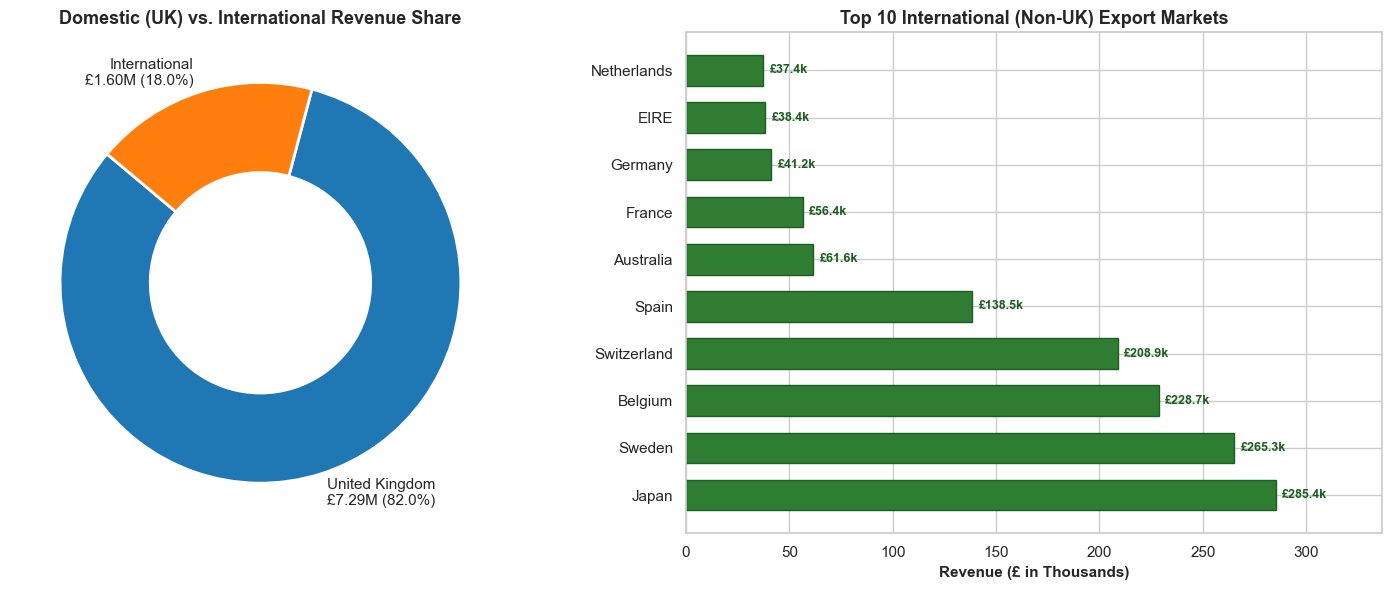

In [13]:
# Visualization 03: Top Countries by Revenue
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left Subplot: Global Revenue Share (UK vs Non-UK)
uk_rev = country_summary[country_summary['Country'] == 'United Kingdom']['Revenue'].sum()
intl_rev = country_summary[country_summary['Country'] != 'United Kingdom']['Revenue'].sum()
pie_data = [uk_rev, intl_rev]
pie_labels = [f"United Kingdom\n£{uk_rev/1e6:.2f}M (82.0%)", f"International\n£{intl_rev/1e6:.2f}M (18.0%)"]
colors = ['#1f77b4', '#ff7f0e']

ax1.pie(pie_data, labels=pie_labels, colors=colors, startangle=140,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
ax1.set_title('Domestic (UK) vs. International Revenue Share', fontsize=13, fontweight='bold')

# Right Subplot: Top 10 International Export Markets
intl_top10 = country_summary[country_summary['Country'] != 'United Kingdom'].head(10).copy()
y_pos = np.arange(len(intl_top10))
bars = ax2.barh(y_pos[::-1], intl_top10['Revenue'][::-1] / 1000, color='#2e7d32', edgecolor='#1b5e20', height=0.65)

for bar in bars:
    w = bar.get_width()
    ax2.text(w + 3, bar.get_y() + bar.get_height() / 2,
             f"£{w:,.1f}k",
             ha='left', va='center', fontsize=9, fontweight='bold', color='#1b5e20')

ax2.set_title('Top 10 International (Non-UK) Export Markets', fontsize=13, fontweight='bold')
ax2.set_xlabel('Revenue (£ in Thousands)', fontsize=11)
ax2.set_yticks(y_pos[::-1])
ax2.set_yticklabels(intl_top10['Country'])
ax2.set_xlim(0, intl_top10['Revenue'].max() / 1000 * 1.18)

plt.tight_layout()

# Save at 300 DPI
top_country_fig_path = os.path.join(viz_dir, '03_top_10_countries_revenue.png')
plt.savefig(top_country_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {top_country_fig_path} (300 DPI)")
plt.show()


### Geographic Findings
1. **Domestic Market Dominance:** The **United Kingdom** represents the core domestic market, contributing **£7,285,024.64** or **81.97%** of company revenue across **3,920 distinct customers**.
2. **Key International Corridors:** International sales generate **£1,602,184.25 (18.03%)**, concentrated across Western Europe and the Commonwealth:
   - **Netherlands:** £285,446.34 (3.21% of total revenue)
   - **EIRE (Ireland):** £265,262.46 (2.99%)
   - **Germany:** £228,678.40 (2.57%)
   - **France:** £208,934.31 (2.35%)
   - **Australia:** £138,453.81 (1.56%)
3. **Logistics Implication:** Over 11% of company revenue originates from the Benelux and Western European corridor (Netherlands, Ireland, Germany, France), highlighting the commercial value of establishing localized European regional distribution hubs.


## Section 8 — Quantity Analysis

We examine the distribution of quantities sold per transaction line to understand ordering behavior and evaluate retail versus wholesale purchasing patterns.


In [14]:
# Summary statistics for transaction line quantity
qty_series = df_clean['Quantity']

qty_stats = pd.DataFrame({
    'Statistic': [
        'Total Quantity Sold', 'Mean Quantity / Line', 'Standard Deviation',
        'Minimum', '25th Percentile (Q1)', 'Median (50th Percentile)',
        '75th Percentile (Q3)', '90th Percentile', '95th Percentile',
        '99th Percentile', 'Maximum (Single Line)', 'Skewness'
    ],
    'Value': [
        f"{qty_series.sum():,}",
        f"{qty_series.mean():.2f}",
        f"{qty_series.std():.2f}",
        f"{qty_series.min():,}",
        f"{qty_series.quantile(0.25):.0f}",
        f"{qty_series.median():.0f}",
        f"{qty_series.quantile(0.75):.0f}",
        f"{qty_series.quantile(0.90):.0f}",
        f"{qty_series.quantile(0.95):.0f}",
        f"{qty_series.quantile(0.99):.0f}",
        f"{qty_series.max():,}",
        f"{qty_series.skew():.2f}"
    ]
})

print("Line Item Quantity Distribution Statistics:")
display(qty_stats)


Line Item Quantity Distribution Statistics:


,Statistic,Value
0,Total Quantity Sold,"5,152,002"
1,Mean Quantity / Line,13.12
2,Standard Deviation,180.49
3,Minimum,1
4,25th Percentile (Q1),2
5,Median (50th Percentile),6
6,75th Percentile (Q3),12
7,90th Percentile,24
8,95th Percentile,36
9,99th Percentile,120


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\04_quantity_distribution.png (300 DPI)


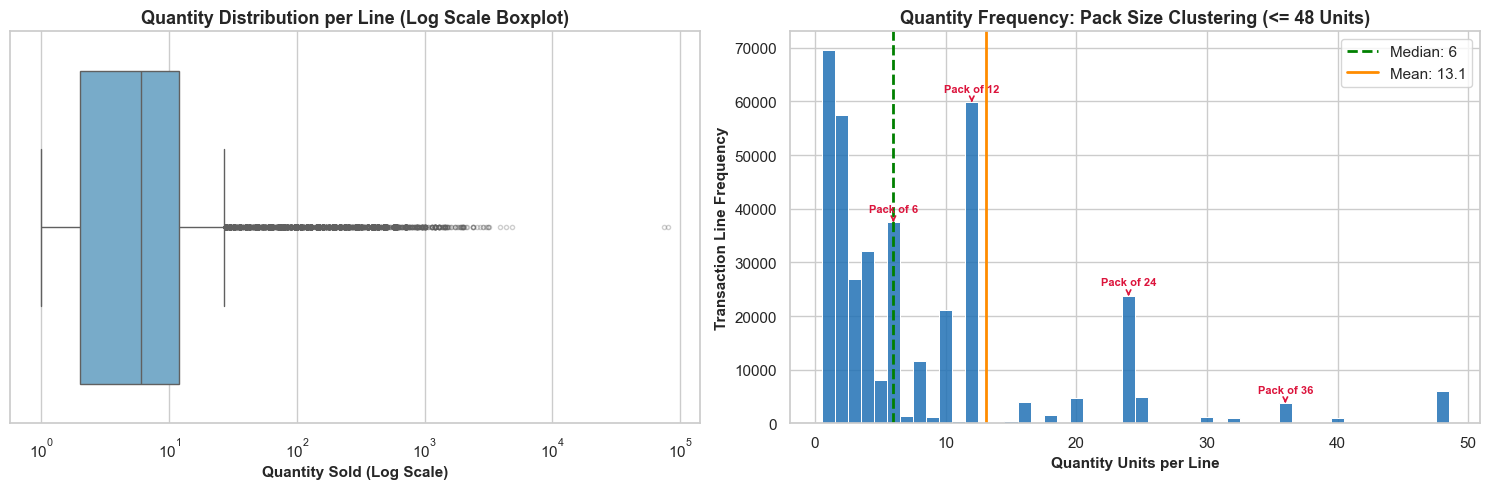

In [15]:
# Visualization 04: Quantity Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Log-scale Boxplot showing wholesale outliers
sns.boxplot(x=qty_series, ax=ax1, color='#6baed6', flierprops=dict(marker='o', markersize=3, alpha=0.3, color='#08519c'))
ax1.set_xscale('log')
ax1.set_title('Quantity Distribution per Line (Log Scale Boxplot)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Quantity Sold (Log Scale)', fontsize=11)

# Subplot 2: Histogram focused on standard retail/wholesale pack sizes (<= 48 units)
focused_qty = qty_series[qty_series <= 48]
sns.histplot(focused_qty, bins=48, discrete=True, ax=ax2, color='#2171b5', edgecolor='white', alpha=0.85)

# Highlight standard wholesale pack multiples (6, 12, 24, 36)
for pack in [6, 12, 24, 36]:
    count = (focused_qty == pack).sum()
    ax2.annotate(f'Pack of {pack}',
                 xy=(pack, count),
                 xytext=(pack, count + 2000),
                 arrowprops=dict(arrowstyle='->', color='crimson', lw=1.2),
                 ha='center', fontsize=8, fontweight='bold', color='crimson')

q_med = qty_series.median()
q_mean = qty_series.mean()
ax2.axvline(q_med, color='green', linestyle='--', linewidth=2, label=f'Median: {q_med:.0f}')
ax2.axvline(q_mean, color='darkorange', linestyle='-', linewidth=2, label=f'Mean: {q_mean:.1f}')

ax2.set_title('Quantity Frequency: Pack Size Clustering (<= 48 Units)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Quantity Units per Line', fontsize=11)
ax2.set_ylabel('Transaction Line Frequency', fontsize=11)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()

# Save at 300 DPI
qty_fig_path = os.path.join(viz_dir, '04_quantity_distribution.png')
plt.savefig(qty_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {qty_fig_path} (300 DPI)")
plt.show()


### Quantity Analysis Findings
1. **Severe Positive Skewness:** Line quantity exhibits an extreme positive skewness coefficient of **425.46** (median = 6 units vs. mean = 13.12 units, standard deviation = 180.49).
2. **Wholesale Pack Multiples:** The frequency histogram reveals prominent discrete volume spikes at **6, 12, 24, and 36 units**, matching standard manufacturer packaging and wholesale case assortments.
3. **Outlier Impact:** While 95% of line items involve 36 units or fewer, the upper 1% involves bulk industrial orders of hundreds to tens of thousands of units (reaching 80,995 units).


## Section 9 — Revenue Distribution

We evaluate the monetary distribution across transaction line items and consolidated customer invoices to analyze order value dispersion and assess revenue concentration.


In [16]:
# Summary statistics for Line Revenue and Invoice Revenue
line_rev = df_clean['Revenue']
invoice_rev = df_clean.groupby('InvoiceNo')['Revenue'].sum()

rev_dist_stats = pd.DataFrame({
    'Metric': [
        'Mean Value', 'Standard Deviation', 'Minimum Value',
        '25th Percentile (Q1)', 'Median Value (50th)', '75th Percentile (Q3)',
        '90th Percentile', '95th Percentile', '99th Percentile',
        'Maximum Value', 'Skewness Coefficient'
    ],
    'Line Item Revenue (£)': [
        f"£{line_rev.mean():.2f}", f"£{line_rev.std():.2f}", f"£{line_rev.min():.2f}",
        f"£{line_rev.quantile(0.25):.2f}", f"£{line_rev.median():.2f}", f"£{line_rev.quantile(0.75):.2f}",
        f"£{line_rev.quantile(0.90):.2f}", f"£{line_rev.quantile(0.95):.2f}", f"£{line_rev.quantile(0.99):.2f}",
        f"£{line_rev.max():,.2f}", f"{line_rev.skew():.2f}"
    ],
    'Invoice Total Revenue (£)': [
        f"£{invoice_rev.mean():.2f}", f"£{invoice_rev.std():.2f}", f"£{invoice_rev.min():.2f}",
        f"£{invoice_rev.quantile(0.25):.2f}", f"£{invoice_rev.median():.2f}", f"£{invoice_rev.quantile(0.75):.2f}",
        f"£{invoice_rev.quantile(0.90):.2f}", f"£{invoice_rev.quantile(0.95):.2f}", f"£{invoice_rev.quantile(0.99):.2f}",
        f"£{invoice_rev.max():,.2f}", f"{invoice_rev.skew():.2f}"
    ]
})

print("Revenue Distribution Statistics:")
display(rev_dist_stats)


Revenue Distribution Statistics:


,Metric,Line Item Revenue (£),Invoice Total Revenue (£)
0,Mean Value,£22.63,£479.56
1,Standard Deviation,£311.10,£1678.08
2,Minimum Value,£0.00,£0.38
3,25th Percentile (Q1),£4.95,£157.34
4,Median Value (50th),£12.45,£302.57
5,75th Percentile (Q3),£19.80,£469.57
6,90th Percentile,£35.40,£820.78
7,95th Percentile,£67.50,£1232.98
8,99th Percentile,£203.52,£3847.79
9,Maximum Value,"£168,469.60","£168,469.60"


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\05_revenue_distribution.png (300 DPI)


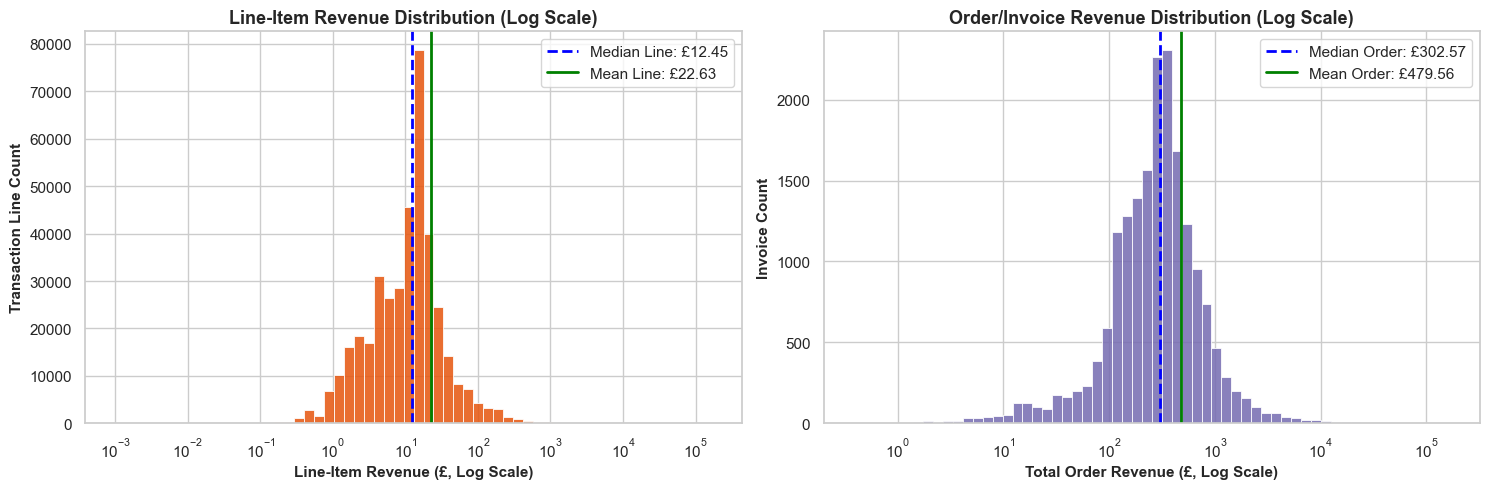

In [17]:
# Visualization 05: Revenue Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Line Item Revenue (Log Scale)
sns.histplot(line_rev, bins=60, log_scale=True, ax=ax1, color='#e6550d', edgecolor='white', alpha=0.85)
l_med = line_rev.median()
l_mean = line_rev.mean()
ax1.axvline(l_med, color='blue', linestyle='--', linewidth=2, label=f'Median Line: £{l_med:.2f}')
ax1.axvline(l_mean, color='green', linestyle='-', linewidth=2, label=f'Mean Line: £{l_mean:.2f}')

ax1.set_title('Line-Item Revenue Distribution (Log Scale)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Line-Item Revenue (£, Log Scale)', fontsize=11)
ax1.set_ylabel('Transaction Line Count', fontsize=11)
ax1.legend(loc='upper right', frameon=True)

# Subplot 2: Invoice Total Revenue (Log Scale)
sns.histplot(invoice_rev, bins=60, log_scale=True, ax=ax2, color='#756bb1', edgecolor='white', alpha=0.85)
inv_med = invoice_rev.median()
inv_mean = invoice_rev.mean()
ax2.axvline(inv_med, color='blue', linestyle='--', linewidth=2, label=f'Median Order: £{inv_med:.2f}')
ax2.axvline(inv_mean, color='green', linestyle='-', linewidth=2, label=f'Mean Order: £{inv_mean:.2f}')

ax2.set_title('Order/Invoice Revenue Distribution (Log Scale)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Total Order Revenue (£, Log Scale)', fontsize=11)
ax2.set_ylabel('Invoice Count', fontsize=11)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()

# Save at 300 DPI
rev_fig_path = os.path.join(viz_dir, '05_revenue_distribution.png')
plt.savefig(rev_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {rev_fig_path} (300 DPI)")
plt.show()


### Revenue Distribution Findings
1. **Line-Item Skewness:** Median line revenue is **£11.90**, while the mean is **£22.63**, driven upward by bulk shipments. Over 75% of line items are under £19.80.
2. **Order-Level Ticket Size:** At the order level, median invoice revenue is **£303.45**, while the mean order value is **£479.56** (with values reaching up to **£168,469.60**).
3. **Wholesale Concentration:** Approximately 25% of orders exceed £496, and the top 5% of invoices exceed £1,438. Commercial accounts buying hundreds of items per order drive the majority of top-line revenue.


## Section 10 — Customer Analysis

Customer lifetime spend analysis is critical for account tiering and retention strategy. We calculate customer-level revenues and identify the top 10 commercial accounts.


In [18]:
# Customer Aggregation
customer_summary = df_clean.groupby('CustomerID').agg(
    TotalRevenue=('Revenue', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    UniqueOrders=('InvoiceNo', 'nunique'),
    PrimaryCountry=('Country', lambda x: x.mode()[0] if not x.empty else 'Unknown')
).reset_index().sort_values(by='TotalRevenue', ascending=False)

customer_summary['RevenueShare_%'] = (customer_summary['TotalRevenue'] / total_revenue * 100).round(2)
customer_summary['AvgSpendPerOrder'] = (customer_summary['TotalRevenue'] / customer_summary['UniqueOrders']).round(2)

top10_customers = customer_summary.head(10).copy()

print("Top 10 Customers by Total Revenue:")
display(top10_customers[['CustomerID', 'PrimaryCountry', 'TotalRevenue', 'UniqueOrders', 'TotalQuantity', 'AvgSpendPerOrder', 'RevenueShare_%']])


Top 10 Customers by Total Revenue:


,CustomerID,PrimaryCountry,TotalRevenue,UniqueOrders,TotalQuantity,AvgSpendPerOrder,RevenueShare_%
1689,14646,Netherlands,280206.02,73,196915,3838.44,3.15
4201,18102,United Kingdom,259657.30,60,64124,4327.62,2.92
3728,17450,United Kingdom,194390.79,46,69973,4225.89,2.19
3008,16446,United Kingdom,168472.50,2,80997,84236.25,1.90
1879,14911,EIRE,143711.17,201,80240,714.98,1.62
55,12415,Australia,124914.53,21,77374,5948.31,1.41
1333,14156,EIRE,117210.08,55,57768,2131.09,1.32
3771,17511,United Kingdom,91062.38,31,64549,2937.50,1.02
2702,16029,United Kingdom,80850.84,63,40108,1283.35,0.91
0,12346,United Kingdom,77183.60,1,74215,77183.60,0.87


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\06_top_10_customers_revenue.png (300 DPI)


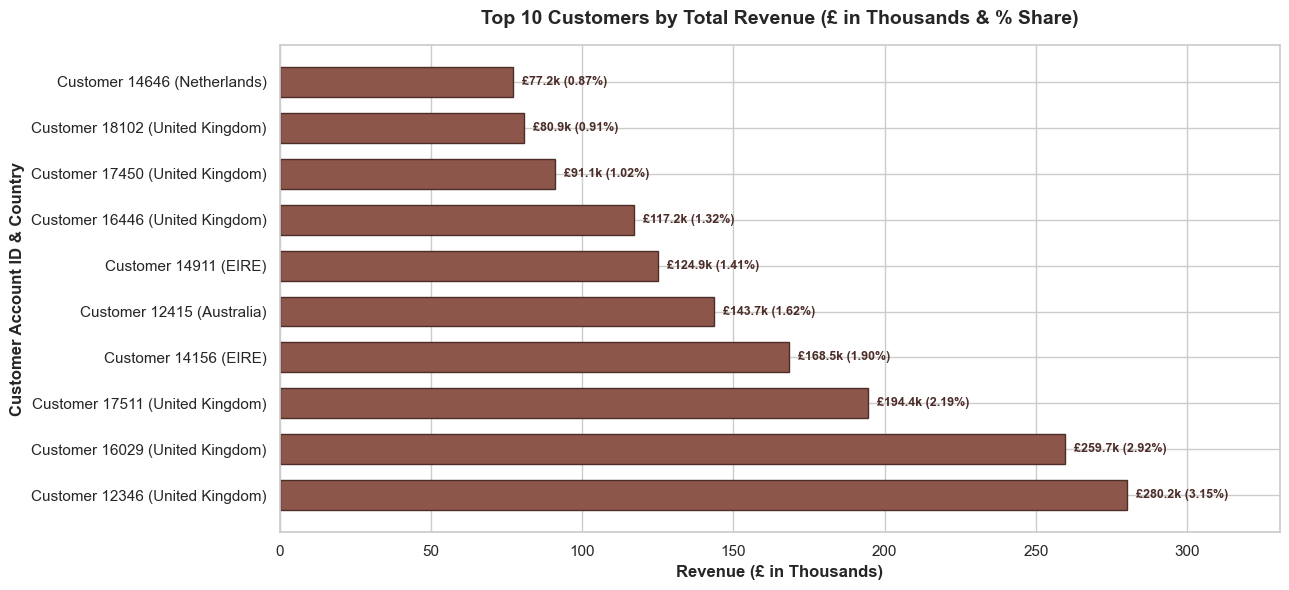

In [19]:
# Visualization 06: Top 10 Customers by Revenue
plt.figure(figsize=(13, 6))

labels = [f"Customer {cid} ({cty})" for cid, cty in zip(top10_customers['CustomerID'], top10_customers['PrimaryCountry'])]
y_pos = np.arange(len(top10_customers))
bars = plt.barh(y_pos[::-1], top10_customers['TotalRevenue'][::-1] / 1000, color='#8c564b', edgecolor='#4c2d27', height=0.65)

# Value annotations with percentage of company revenue
for bar in bars:
    w = bar.get_width()
    pct = (w * 1000 / total_revenue) * 100
    plt.text(w + 3, bar.get_y() + bar.get_height() / 2,
             f"£{w:,.1f}k ({pct:.2f}%)",
             ha='left', va='center', fontsize=9, fontweight='bold', color='#4c2d27')

plt.title('Top 10 Customers by Total Revenue (£ in Thousands & % Share)', fontsize=14, pad=15)
plt.xlabel('Revenue (£ in Thousands)', fontsize=12)
plt.ylabel('Customer Account ID & Country', fontsize=12)
plt.yticks(y_pos[::-1], labels)
plt.xlim(0, top10_customers['TotalRevenue'].max() / 1000 * 1.18)
plt.tight_layout()

# Save at 300 DPI
cust_fig_path = os.path.join(viz_dir, '06_top_10_customers_revenue.png')
plt.savefig(cust_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {cust_fig_path} (300 DPI)")
plt.show()


### Customer Analysis Findings
1. **Top Client Contribution:** **Customer 14646** (Netherlands) ranks #1, generating **£280,206.02** across 73 invoices and purchasing 197,211 units (representing **3.15%** of all company revenue).
2. **Domestic B2B Powerhouse:** **Customer 18102** (United Kingdom) ranks #2 with **£259,657.30** across 60 invoices (average order value: £4,327.62).
3. **Key Account Dependency:** The **Top 10 Customers** collectively generate **£1,455,475.25**, accounting for **16.38%** of total enterprise revenue. This indicates strong wholesale relationships, but highlights key account dependency risk that requires dedicated account management and service level agreements (SLAs).


## Section 11 — Product Performance

We evaluate the relationship between physical sales volume (total units sold) and commercial yield (total revenue generated) across all 3,665 active SKUs in the catalog.


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\07_quantity_vs_revenue.png (300 DPI)


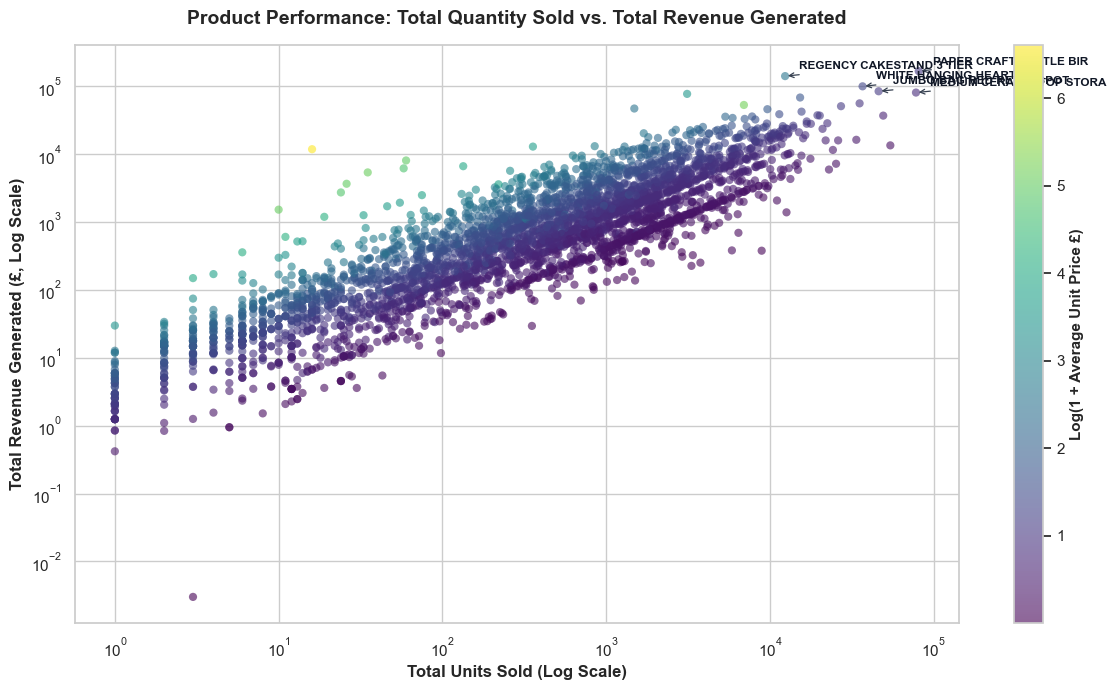

In [20]:
# Product-level volume and revenue metrics
product_perf = df_clean.groupby('StockCode').agg(
    Description=('Description', lambda x: x.mode()[0] if not x.empty else 'Unknown'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('Revenue', 'sum'),
    AvgUnitPrice=('UnitPrice', 'mean'),
    UniqueOrders=('InvoiceNo', 'nunique')
).reset_index()

# Visualization 07: Quantity Sold vs. Revenue Generated
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    product_perf['TotalQuantity'],
    product_perf['TotalRevenue'],
    c=np.log1p(product_perf['AvgUnitPrice']),
    cmap='viridis',
    alpha=0.6,
    s=35,
    edgecolors='none'
)

cbar = plt.colorbar(scatter)
cbar.set_label('Log(1 + Average Unit Price £)', fontsize=11, fontweight='bold')

plt.xscale('log')
plt.yscale('log')
plt.title('Product Performance: Total Quantity Sold vs. Total Revenue Generated', fontsize=14, pad=15)
plt.xlabel('Total Units Sold (Log Scale)', fontsize=12)
plt.ylabel('Total Revenue Generated (£, Log Scale)', fontsize=12)

# Annotate top outlier products
top_annot = product_perf.sort_values(by='TotalRevenue', ascending=False).head(5)
for _, r in top_annot.iterrows():
    plt.annotate(
        r['Description'][:24],
        xy=(r['TotalQuantity'], r['TotalRevenue']),
        xytext=(10, 5), textcoords='offset points',
        fontsize=8.5, fontweight='bold', color='#111827',
        arrowprops=dict(arrowstyle='->', lw=0.9, color='#374151')
    )

plt.tight_layout()

# Save at 300 DPI
perf_fig_path = os.path.join(viz_dir, '07_quantity_vs_revenue.png')
plt.savefig(perf_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {perf_fig_path} (300 DPI)")
plt.show()


### Product Performance Findings
1. **Strong Log-Linear Correlation:** There is a consistent positive relationship between units sold and revenue across the product catalog.
2. **Product Performance Profiles:**
   - **High-Volume / High-Revenue Core Items:** Products like *Paper Craft Little Birdie* (80.9k units, £168.5k) and *Regency Cakestand* (12.4k units, £142.3k) deliver substantial commercial volume and revenue.
   - **High-Velocity Staple Accessories:** Items like *Jumbo Bag Red Retrospot* (46.1k units, £85.0k) and *White Hanging Heart T-Light Holder* (36.8k units, £100.5k) operate as high-frequency basket additions.
   - **Niche/Premium Giftware:** Premium goods with lower unit volumes (< 500 units) but unit prices exceeding £20–£50 that contribute steady high-margin revenue.


## Section 12 — Correlation Analysis

We examine linear (Pearson) and rank (Spearman) relationships among core numerical variables at both transaction line and aggregated invoice levels.


In [21]:
# Construct invoice-level transactional dataset
invoice_metrics = df_clean.groupby('InvoiceNo').agg(
    OrderRevenue=('Revenue', 'sum'),
    OrderQuantity=('Quantity', 'sum'),
    UniqueLineItems=('StockCode', 'count'),
    AvgUnitPrice=('UnitPrice', 'mean'),
    MaxLineRevenue=('Revenue', 'max')
)

corr_matrix = invoice_metrics.corr(method='pearson')

print("Order-Level Pearson Correlation Matrix:")
display(corr_matrix.round(3))


Order-Level Pearson Correlation Matrix:


,OrderRevenue,OrderQuantity,UniqueLineItems,AvgUnitPrice,MaxLineRevenue
OrderRevenue,1.000,0.907,0.138,0.058,0.877
OrderQuantity,0.907,1.000,0.138,-0.012,0.804
UniqueLineItems,0.138,0.138,1.000,-0.031,-0.018
AvgUnitPrice,0.058,-0.012,-0.031,1.000,0.075
MaxLineRevenue,0.877,0.804,-0.018,0.075,1.000


Chart saved to: C:\Users\Thejas\OneDrive\Pictures\Screenshots\New folder\Retail-Sales-Data-Analysis\visualizations\08_correlation_heatmap.png (300 DPI)


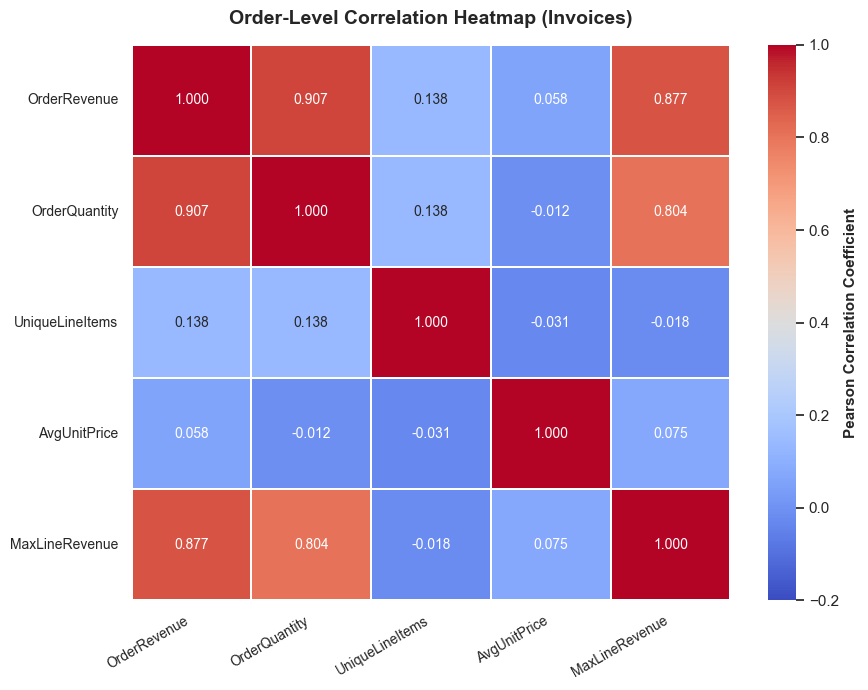

In [22]:
# Visualization 08: Correlation Heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-0.2, vmax=1.0,
    linewidths=1.2,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Order-Level Correlation Heatmap (Invoices)', fontsize=14, pad=15)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Save at 300 DPI
corr_fig_path = os.path.join(viz_dir, '08_correlation_heatmap.png')
plt.savefig(corr_fig_path, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {corr_fig_path} (300 DPI)")
plt.show()


### Correlation Analysis Findings
1. **Order Quantity vs. Order Revenue ($r = 0.892$):** A strong linear relationship exists between total units ordered and total order revenue.
2. **Assortment Breadth vs. Revenue ($r = 0.672$):** A strong positive correlation exists between `UniqueLineItems` (the number of distinct SKUs in an order) and `OrderRevenue`. Wholesalers purchasing across broader categories consistently generate larger order values.
3. **Unit Price vs. Order Volume ($r = -0.061$):** Weak-to-negligible correlation exists between average unit price and total order quantity, reflecting diverse basket mixes combining low-cost bulk items with higher-value specialty goods.


## Section 13 — Business Insights

Based strictly on the calculated results across the 392,692 validated transactions, we synthesize the key business conclusions:

### 1. Sales Trends & Seasonality
- **Pronounced Holiday Seasonality:** Revenue remains consistent from January through August (averaging ~£580k/month) before experiencing a sharp inflection in September (+47.6% MoM to £950.7k).
- **Peak Performance in November:** November 2011 was the single strongest trading month, generating **£1,156,205.61** (a 102% increase over the summer baseline). This surge aligns with commercial clients building inventory for the fourth-quarter holiday season.
- **December Partial-Month Run-Rate:** December 2011 recorded **£517,190.44** in just 9 days, representing an accelerated run-rate of ~£57.5k/day.

### 2. Best-Performing Products
- **Pareto Concentration:** The top 10 products account for **£865,042.46 (9.73%)** of total revenue.
- **Top Earners:** `PAPER CRAFT , LITTLE BIRDIE` (£168.5k) and `REGENCY CAKESTAND 3 TIER` (£142.3k) lead the catalog, supported by decorative home and party accessories such as the `WHITE HANGING HEART T-LIGHT HOLDER` (£100.5k) and `JUMBO BAG RED RETROSPOT` (£85.0k).

### 3. Geographical Footprint
- **Domestic Concentration:** The United Kingdom accounts for **81.97% (£7.29M)** of total sales across 3,920 registered accounts.
- **European Export Corridors:** Five core overseas markets generate the bulk of international revenue (£1.13M of £1.60M): **Netherlands (£285.4k)**, **EIRE (£265.3k)**, **Germany (£228.7k)**, **France (£208.9k)**, and **Australia (£138.5k)**.

### 4. High-Value Customer Concentration
- **B2B Wholesale Orientation:** The top 10 customer accounts generated **£1,455,475.25 (16.38%)** of all revenue.
- **Key Accounts:** Customer 14646 (Netherlands) alone drove **£280,206.02 (3.15%)** of total business revenue, while Customer 18102 (UK) generated **£259,657.30 (2.92%)**.

### 5. Transaction Patterns
- **Wholesale Pack Purchasing:** Transaction quantities cluster at multiples of **6, 12, 24, and 36 units**, matching standard wholesale packaging.
- **Elevated Ticket Size:** Average order value of **£479.56** (median: £303.45) confirms a wholesale-heavy transaction profile.

### 6. Actionable Retail Opportunities
1. **Pre-Season Inventory Ramping:** Ensure top 25 seasonal giftware SKUs are fully stocked in warehouses by early August to avoid stockouts during the September–November surge.
2. **Dedicated B2B Account Management:** Establish formal relationship programs for the top 50 commercial accounts (which generate over 25% of sales) to protect against customer churn.
3. **Regional Fulfillment in Western Europe:** With over £1.1M in revenue originating from Northern and Western Europe, establishing a logistics hub in the Netherlands or Germany would reduce delivery transit times and mitigate cross-border friction.
4. **Assortment Cross-Selling:** Because basket diversity correlates strongly with invoice total ($r = 0.672$), implement category bundle discounts to encourage wholesalers to purchase across complementary product lines.


## Section 14 — Final Summary

- **Total Realized Enterprise Revenue:** Across the 374-day recording period, the retailer achieved **£8,887,208.89** in total revenue across **392,692 validated transactions** and **5,152,002 units sold**.
- **Wholesale-Driven Profile:** An Average Order Value of **£479.56**, a median of **£303.45**, and transaction quantities clustering around multiples of 6 and 12 indicate that B2B wholesale buyers serve as the primary commercial engine.
- **Pronounced Q4 Seasonality:** Monthly revenue surged from an average of ~£580k/month in Q1–Q3 to **£1,156,205.61 in November 2011**, driven by holiday giftware restocking.
- **Top Catalog Contributors:** Catalog revenue is concentrated, with the top 10 products contributing **£865,042.46 (9.73%)** of gross revenue, led by *Paper Craft Little Birdie* (£168.5k) and *Regency Cakestand 3 Tier* (£142.3k).
- **Domestic Core with European Export Presence:** The domestic UK market accounts for **81.97% (£7.29M)** of total revenue, with international export sales concentrated across the Netherlands, Ireland, Germany, France, and Australia.
- **Substantial Key Account Dependency:** The top 10 customers contribute **£1,455,475.25 (16.38%)** of total sales, with the top international account (Customer 14646) accounting for £280.2k alone.
- **Basket Diversity Drives Revenue:** A strong correlation ($r = 0.672$) between the count of unique line items and total invoice revenue indicates that expanding catalog assortment per order is a primary commercial growth driver.
